# Network Intrusion Detection Using Machine Learning
| Section | What happens |
|---|---|
| A | Check Python + libraries |
| B | Load dataset and inspect it |
| C | Exploratory data analysis (EDA) |
| D | Clean data + prepare target label |
| E | Train / test split |
| F | Build the preprocessing pipeline |
| G | Train and compare models |
| H | Evaluate the final model |
| I | External test on the official testing file |
| J | Predictions on unseen samples |
| K | Save model |
| L | Load saved model and test again |
| M | Save results |

## A. Environment and library verification

In [1]:
import sys, platform
from pathlib import Path

import numpy as np, pandas as pd, sklearn, matplotlib, seaborn, joblib
import matplotlib.pyplot as plt
import seaborn as sns

# --- make the project's src/ folder importable (works if notebook is in notebooks/) ---
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

print("Python      :", sys.version.split()[0])
print("Platform    :", platform.platform())
print("pandas      :", pd.__version__)
print("numpy       :", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("matplotlib  :", matplotlib.__version__)
print("seaborn     :", seaborn.__version__)
print("joblib      :", joblib.__version__)
print("Project root:", ROOT)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)

Python      : 3.12.3
Platform    : Linux-6.18.44-fc-v114-x86_64-with-glibc2.39
pandas      : 3.0.2
numpy       : 2.4.4
scikit-learn: 1.8.0
matplotlib  : 3.10.8
seaborn     : 0.13.2
joblib      : 1.5.3
Project root: /home/claude/build/NetworkIntrusionDetection


## B. Dataset loading and validation
We use the **official training/testing partition of UNSW-NB15** (UNSW Canberra Cyber).
Source: <https://research.unsw.edu.au/projects/unsw-nb15-dataset> - free for academic use, please cite *Moustafa & Slay, MilCIS 2015*.
The two CSV files must be inside the `dataset/` folder. If they are missing, run `python src/download_dataset.py` in Terminal or follow `dataset/README.md`.

In [2]:
from data_preprocessing import (TRAIN_CSV, OFFICIAL_TEST_CSV, RANDOM_STATE, CLASS_NAMES,
                                load_raw_csv, validate_labels, clean_dataset, split_data,
                                build_preprocessor, get_models, make_pipeline, numeric_columns,
                                rows_not_seen_in_training, CATEGORICAL_COLS,
                                MODEL_PATH, OUTPUTS_DIR)
OUTPUTS_DIR.mkdir(exist_ok=True)

for f in (TRAIN_CSV, OFFICIAL_TEST_CSV):
    print(("FOUND   " if f.exists() else "MISSING ") + str(f))

df = load_raw_csv(TRAIN_CSV)          # raises a helpful FileNotFoundError if the file is missing
print("\nDataset loaded successfully!")

FOUND   /home/claude/build/NetworkIntrusionDetection/dataset/UNSW_NB15_training-set.csv
FOUND   /home/claude/build/NetworkIntrusionDetection/dataset/UNSW_NB15_testing-set.csv



Dataset loaded successfully!


In [3]:
print("Shape (rows, columns):", df.shape)
print("\nColumn names and data types:")
print(df.dtypes.to_string())

Shape (rows, columns): (175341, 45)

Column names and data types:
id                     int64
dur                  float64
proto                    str
service                  str
state                    str
spkts                  int64
dpkts                  int64
sbytes                 int64
dbytes                 int64
rate                 float64
sttl                   int64
dttl                   int64
sload                float64
dload                float64
sloss                  int64
dloss                  int64
sinpkt               float64
dinpkt               float64
sjit                 float64
djit                 float64
swin                   int64
stcpb                  int64
dtcpb                  int64
dwin                   int64
tcprtt               float64
synack               float64
ackdat               float64
smean                  int64
dmean                  int64
trans_depth            int64
response_body_len      int64
ct_srv_src             int64
ct_sta

In [4]:
df.head()

,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,dload,sloss,dloss,sinpkt,dinpkt,sjit,djit,swin,stcpb,dtcpb,dwin,tcprtt,synack,ackdat,smean,dmean,trans_depth,response_body_len,ct_srv_src,ct_state_ttl,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,252,254,14158.942380,8495.365234,0,0,24.295600,8.375000,30.177547,11.830604,255,621772692,2202533631,255,0.000000,0.000000,0.000000,43,43,0,0,1,0,1,1,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,62,252,8395.112305,503571.312500,2,17,49.915000,15.432865,61.426934,1387.778330,255,1417884146,3077387971,255,0.000000,0.000000,0.000000,52,1106,0,0,43,1,1,1,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,62,252,1572.271851,60929.230470,1,6,231.875571,102.737203,17179.586860,11420.926230,255,2116150707,2963114973,255,0.111897,0.061458,0.050439,46,824,0,0,7,1,2,1,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,62,252,2740.178955,3358.622070,1,3,152.876547,90.235726,259.080172,4991.784669,255,1107119177,1047442890,255,0.000000,0.000000,0.000000,52,64,0,0,1,1,2,1,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,254,252,8561.499023,3987.059814,2,1,47.750333,75.659602,2415.837634,115.807000,255,2436137549,1977154190,255,0.128381,0.071147,0.057234,53,45,0,0,43,1,2,2,1,40,0,0,0,2,39,0,Normal,0


### Data dictionary (what the important columns mean)
| Column | Meaning |
|---|---|
| `id` | Row number (**dropped** - carries no information) |
| `dur`, `rate` | Duration of the flow, packets per second |
| `proto`, `service`, `state` | **Categorical:** protocol (tcp/udp...), service (http/dns...), connection state (FIN, INT...) |
| `spkts`, `dpkts`, `sbytes`, `dbytes` | Packets / bytes from source (s) and destination (d) |
| `sttl`, `dttl` | Time-to-live values of source / destination |
| `sload`, `dload` | Bits per second from source / destination |
| `sinpkt`, `dinpkt`, `sjit`, `djit` | Inter-packet arrival time and jitter |
| `tcprtt`, `synack`, `ackdat` | TCP round-trip-time measurements |
| `ct_*` | Connection-count features (how many similar connections happened recently) |
| `attack_cat` | Traffic family: `Normal` or one of 9 attack types (**dropped** - it reveals the answer) |
| **`label`** | **TARGET: 0 = Normal, 1 = Attack** |

## C. Exploratory data analysis (EDA)

In [5]:
print("Missing values in the whole file :", int(df.isna().sum().sum()))
print("Infinite values                  :", int(np.isinf(df.select_dtypes('number')).sum().sum()))
print("Duplicate rows (ignoring id & attack_cat):",
      int(df.drop(columns=['id', 'attack_cat']).duplicated().sum()))
print("\nUnique values in categorical columns:")
print(df[CATEGORICAL_COLS].nunique().to_string())

Missing values in the whole file : 0
Infinite values                  : 0


Duplicate rows (ignoring id & attack_cat): 74072

Unique values in categorical columns:
proto      133
service     13
state        9


### Label check
The target is `label`. Before using it, we **verify** with the dataset's own `attack_cat` column that `label = 0` means *Normal* and `label = 1` means *one of the nine attack families* - we do not simply assume it.

In [6]:
check = validate_labels(df)      # raises an error if the mapping is inconsistent
print("Label mapping verified: label 0 == 'Normal' only, label 1 == attack families only\n")
check

Label mapping verified: label 0 == 'Normal' only, label 1 == attack families only



label,0,1
attack_cat,,
Analysis,0,2000
Backdoor,0,1746
DoS,0,12264
Exploits,0,33393
Fuzzers,0,18184
Generic,0,40000
Normal,56000,0
Reconnaissance,0,10491
Shellcode,0,1133


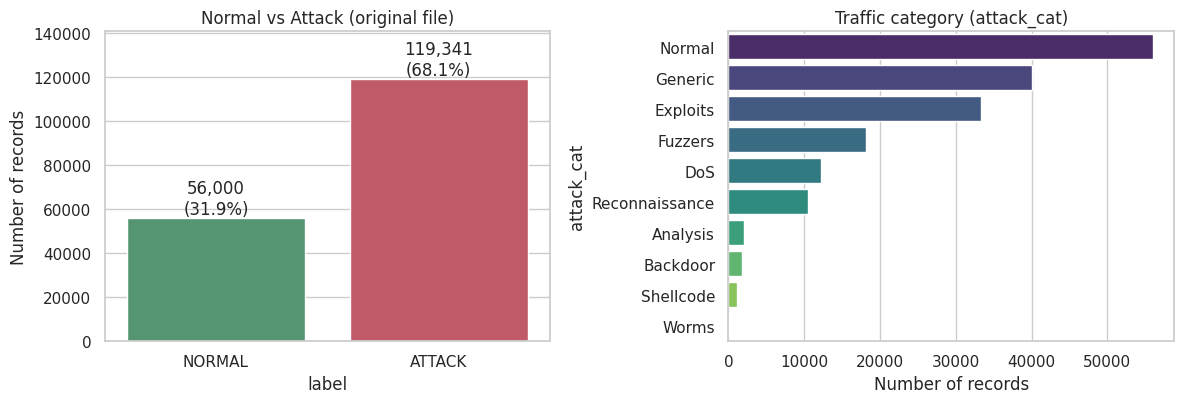

In [7]:
from evaluate_model import plot_class_distribution
fig = plot_class_distribution(df["label"], "Normal vs Attack (original file)",
                              OUTPUTS_DIR / "class_distribution.png", attack_cat=df["attack_cat"])
plt.show()

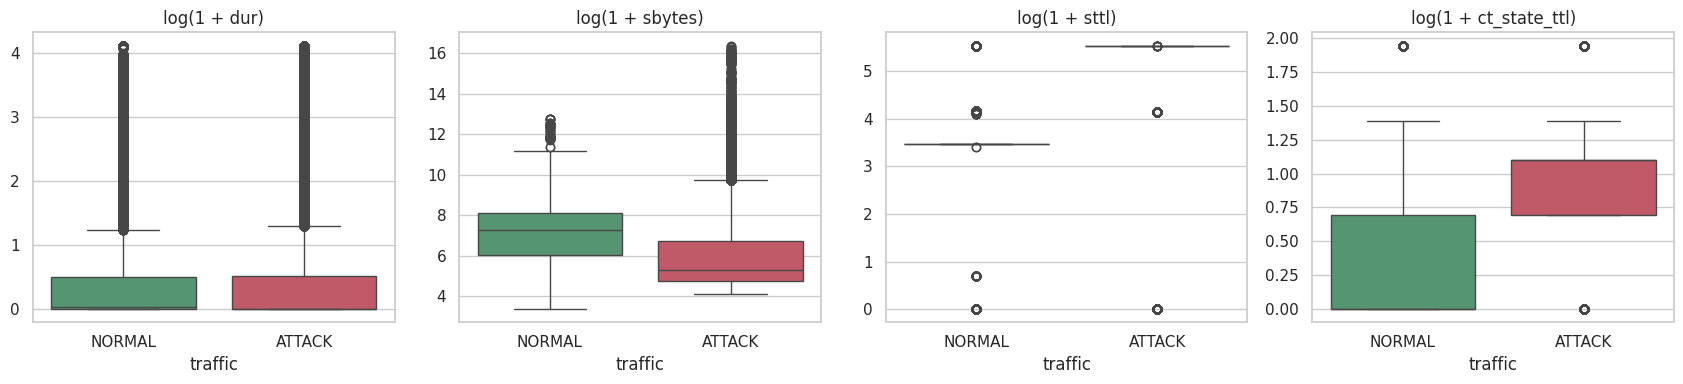

In [8]:
# A few features compared between Normal and Attack traffic (log scale because values are very skewed)
plot_df = df.assign(traffic=df["label"].map(CLASS_NAMES))
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, col in zip(axes, ["dur", "sbytes", "sttl", "ct_state_ttl"]):
    sns.boxplot(data=plot_df, x="traffic", y=np.log1p(plot_df[col]), hue="traffic",
                palette=["#4c9f70", "#d1495b"], legend=False, ax=ax)
    ax.set_title(f"log(1 + {col})")
    ax.set_ylabel("")
plt.tight_layout(); plt.show()

In [9]:
# Which protocols / states are most common, and what share of each is attack?
for col in ["proto", "state"]:
    top = df[col].value_counts().head(6).index
    share = df[df[col].isin(top)].groupby(col)["label"].mean().sort_values(ascending=False)
    print(f"Attack share (%) among the 6 most common '{col}' values:")
    print((share * 100).round(1).to_string(), "\n")

Attack share (%) among the 6 most common 'proto' values:
proto
unas    100.0
sctp    100.0
ospf     97.5
udp      78.0
tcp      51.1
arp       0.0 

Attack share (%) among the 6 most common 'state' values:
state
INT    93.1
REQ    53.5
FIN    52.2
RST    14.5
CON     8.0
ECO     0.0 



## D. Data cleaning and target-label preparation
`clean_dataset()` does the following:
1. drops `id` (row counter) and `attack_cat` (**leaks the answer**),
2. converts infinite values to NaN (none exist here, but the code is safe),
3. removes **exact duplicate rows** - otherwise the same record could appear in both training and test sets,
4. returns the features `X` and the 0/1 target `y`.

**Label mapping used:** `0 → NORMAL`, `1 → ATTACK`.

In [10]:
X, y = clean_dataset(df)
print("\nTarget mapping:", CLASS_NAMES)
print("Class counts after cleaning:")
print(y.map(CLASS_NAMES).value_counts().to_string())
print("\nNumber of feature columns:", X.shape[1])
print("Categorical features:", CATEGORICAL_COLS)
print("Numeric features    :", len(numeric_columns(X)))

Rows before cleaning  : 175,341
Duplicate rows removed: 74,072
Rows after cleaning   : 101,269

Target mapping: {0: 'NORMAL', 1: 'ATTACK'}
Class counts after cleaning:
label
NORMAL    51890
ATTACK    49379

Number of feature columns: 42
Categorical features: ['proto', 'service', 'state']
Numeric features    : 39


> **Note on class balance:** the original file is imbalanced (~68 % attack), but after removing duplicates the two classes are almost balanced. Even so, we do **not** rely on accuracy alone - we also report precision, recall and F1 for the ATTACK class, and we use `class_weight='balanced'` in the models (this only changes the training loss, so it cannot leak test data).

## E. Train-test split
80 % training / 20 % testing, **stratified** (same Normal : Attack ratio in both parts) with a fixed random seed.
The 20 % test part is kept untouched until the final evaluation.

In [11]:
X_train, X_test, y_train, y_test = split_data(X, y)
print(f"Training set: {X_train.shape[0]:,} rows | Test set: {X_test.shape[0]:,} rows")
print("\nAttack share in training set: {:.2f} %".format(y_train.mean() * 100))
print("Attack share in test set    : {:.2f} %".format(y_test.mean() * 100))

Training set: 81,015 rows | Test set: 20,254 rows

Attack share in training set: 48.76 %
Attack share in test set    : 48.76 %


## F. Preprocessing pipeline (no data leakage)
* Numeric features: median imputation → `log1p` (tames huge values) → `StandardScaler`
* Categorical features (`proto`, `service`, `state`): One-Hot encoding (rare values grouped, unseen values handled)

The preprocessor is placed **inside a scikit-learn `Pipeline`**, so it is fitted **only on training data** (and, during cross-validation, only on each training fold).

In [12]:
pre = build_preprocessor(X_train)
pre.fit(X_train)                      # fitted on TRAINING data only
Xt = pre.transform(X_train)
print("Before preprocessing:", X_train.shape, "-> after:", Xt.shape)
print("(42 original features became", Xt.shape[1], "columns after one-hot encoding)")
pre

Before preprocessing: (81015, 42) -> after: (81015, 62)
(42 original features became 62 columns after one-hot encoding)


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. `

## G. Train and compare the machine-learning models
Three classifiers are compared using **5-fold stratified cross-validation on the training part only**.
The test part is *not* used for choosing the model - this keeps the final test score honest.

In [13]:
import time
from sklearn.model_selection import StratifiedKFold, cross_validate

SCORING = {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1"}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rows = []
for name, clf in get_models().items():
    t0 = time.time()
    res = cross_validate(make_pipeline(X_train, clf), X_train, y_train, cv=cv, scoring=SCORING)
    rows.append({"model": name, **{k: res[f"test_{k}"].mean() for k in SCORING},
                 "f1_std": res["test_f1"].std(), "cv_time_sec": time.time() - t0})
    print(f"{name:<20} finished in {time.time() - t0:5.0f} s")

cv_table = pd.DataFrame(rows)
cv_table.index = cv_table["model"]; cv_table.index.name = None
cv_table.to_csv(OUTPUTS_DIR / "model_comparison.csv", index=False, float_format="%.4f")
cv_table.drop(columns="model").round(4)

Logistic Regression  finished in    13 s


Decision Tree        finished in     9 s


Random Forest        finished in   124 s


,accuracy,precision,recall,f1,f1_std,cv_time_sec
Logistic Regression,0.9034,0.8638,0.9519,0.9057,0.0030,13.2499
Decision Tree,0.9174,0.8999,0.9346,0.9169,0.0020,9.1032
Random Forest,0.9263,0.9083,0.9442,0.9259,0.0016,123.6584


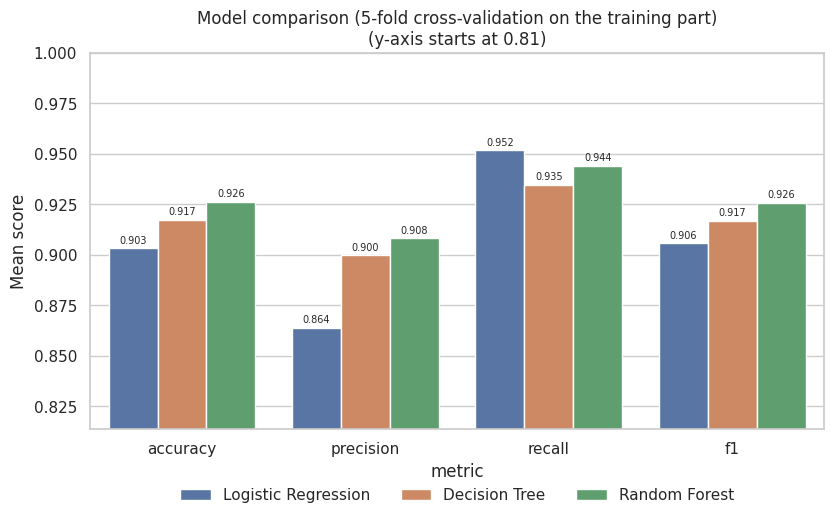

Selected final model (highest mean cross-validation F1): Random Forest


In [14]:
from evaluate_model import plot_model_comparison
fig = plot_model_comparison(cv_table, OUTPUTS_DIR / "model_comparison.png")
plt.show()

best_name = cv_table.sort_values(["f1", "recall"], ascending=False).index[0]
print("Selected final model (highest mean cross-validation F1):", best_name)

## H. Final model - training and evaluation on the untouched test set

In [15]:
from evaluate_model import (evaluate_pipeline, print_metrics, plot_confusion_matrix,
                            get_feature_importance, plot_feature_importance)

final_pipe = make_pipeline(X_train, get_models()[best_name])
final_pipe.fit(X_train, y_train)

metrics_hold, y_pred = evaluate_pipeline(final_pipe, X_test, y_test)
print_metrics(metrics_hold, f"{best_name} - hold-out test set")

=== Random Forest - hold-out test set ===
Samples   : 20,254
Accuracy  : 0.9301  (93.01 %)
Precision : 0.9135  (ATTACK class)
Recall    : 0.9463  (ATTACK class)
F1-score  : 0.9296  (ATTACK class)
ROC-AUC   : 0.9857
False-positive rate: 0.0853


In [16]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred, target_names=["NORMAL", "ATTACK"], digits=4))

              precision    recall  f1-score   support

      NORMAL     0.9471    0.9147    0.9306     10378
      ATTACK     0.9135    0.9463    0.9296      9876

    accuracy                         0.9301     20254
   macro avg     0.9303    0.9305    0.9301     20254
weighted avg     0.9307    0.9301    0.9301     20254



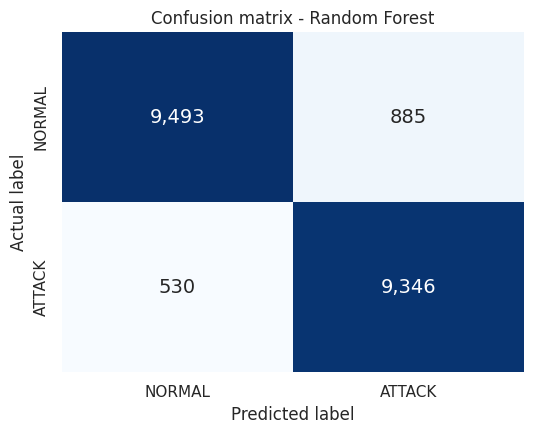

Attacks correctly detected (TP): 9,346   | Attacks MISSED (FN): 530
Normal traffic correctly passed (TN): 9,493 | False alarms (FP): 885


In [17]:
fig = plot_confusion_matrix(y_test, y_pred, f"Confusion matrix - {best_name}",
                            OUTPUTS_DIR / "confusion_matrix.png")
plt.show()
m = metrics_hold
print(f"Attacks correctly detected (TP): {m['TP']:,}   | Attacks MISSED (FN): {m['FN']:,}")
print(f"Normal traffic correctly passed (TN): {m['TN']:,} | False alarms (FP): {m['FP']:,}")

**Why recall matters in intrusion detection:** a *missed attack* (false negative) means a malicious flow passes unnoticed - this is usually the costlier mistake, so we want a high **recall** for the ATTACK class.
**Why false positives also matter:** too many false alarms (low **precision**) flood the security team with harmless alerts and make them ignore real warnings (alert fatigue). **F1-score** balances both.

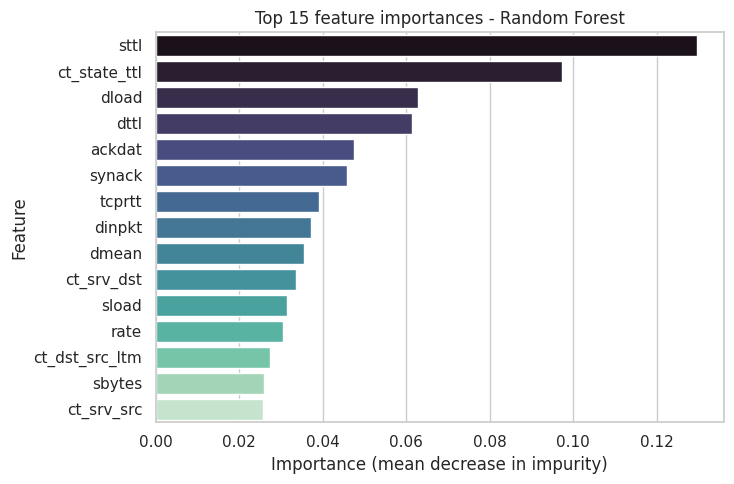

sttl              0.1297
ct_state_ttl      0.0975
dload             0.0629
dttl              0.0614
ackdat            0.0475
synack            0.0459
tcprtt            0.0391
dinpkt            0.0372
dmean             0.0355
ct_srv_dst        0.0336
sload             0.0316
rate              0.0305
ct_dst_src_ltm    0.0273
sbytes            0.0260
ct_srv_src        0.0258


In [18]:
imp = get_feature_importance(final_pipe)
if imp is not None:
    fig = plot_feature_importance(imp, f"Top 15 feature importances - {best_name}",
                                  OUTPUTS_DIR / "feature_importance.png")
    plt.show()
    print(imp.round(4).to_string())
else:
    print(f"{best_name} does not provide feature importances.")

## I. Extra check: official testing file (different traffic distribution)
The creators of UNSW-NB15 also provide a separate **testing-set** CSV. We clean it the same way and **remove records that already occur in the training file**, then test the *already-trained* model on it. Results here are usually lower than on the hold-out split because the official partitions have different traffic distributions - this is a realistic hint of how a model behaves on traffic that differs from its training data.

Official testing file after cleaning: 53,952 rows; 1,304 also occur in training data and were removed -> 52,648 rows used


=== Random Forest - official testing file (external) ===
Samples   : 52,648
Accuracy  : 0.8244  (82.44 %)
Precision : 0.6795  (ATTACK class)
Recall    : 0.9711  (ATTACK class)
F1-score  : 0.7995  (ATTACK class)
ROC-AUC   : 0.9628
False-positive rate: 0.2583


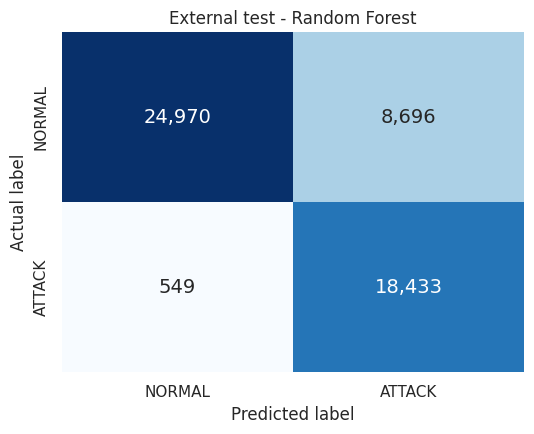

In [19]:
if OFFICIAL_TEST_CSV.exists():
    X_ext, y_ext = clean_dataset(load_raw_csv(OFFICIAL_TEST_CSV), verbose=False)
    n_before = len(X_ext)
    keep = rows_not_seen_in_training(X_ext, X)
    X_ext, y_ext = X_ext[keep], y_ext[keep]
    print(f"Official testing file after cleaning: {n_before:,} rows; "
          f"{n_before - len(X_ext):,} also occur in training data and were removed -> {len(X_ext):,} rows used")
    metrics_ext, y_pred_ext = evaluate_pipeline(final_pipe, X_ext, y_ext)
    print_metrics(metrics_ext, f"{best_name} - official testing file (external)")
    fig = plot_confusion_matrix(y_ext, y_pred_ext, f"External test - {best_name}",
                                OUTPUTS_DIR / "confusion_matrix_external.png")
    plt.show()
else:
    metrics_ext = None
    print("Official testing file not found - skipping this optional check.")

## J. Predictions on unseen test samples
Five random NORMAL and five random ATTACK records are taken from the hold-out **test** set (never seen during training). They are chosen at random - not hand-picked.

In [20]:
sample_idx = pd.concat([y_test[y_test == 0].sample(5, random_state=RANDOM_STATE),
                        y_test[y_test == 1].sample(5, random_state=RANDOM_STATE)]).index
sample_X = X_test.loc[sample_idx]

proba = final_pipe.predict_proba(sample_X)[:, 1]
pred = final_pipe.predict(sample_X)
demo = pd.DataFrame({
    "actual": y_test.loc[sample_idx].map(CLASS_NAMES),
    "predicted": [CLASS_NAMES[p] for p in pred],
    "attack_probability": proba.round(4),
    "proto": sample_X["proto"], "service": sample_X["service"], "state": sample_X["state"],
    "sttl": sample_X["sttl"], "ct_state_ttl": sample_X["ct_state_ttl"],
})
demo["correct"] = demo["actual"] == demo["predicted"]
demo

,actual,predicted,attack_probability,proto,service,state,sttl,ct_state_ttl,correct
44799,NORMAL,ATTACK,0.675,tcp,-,FIN,254,1,False
28884,NORMAL,NORMAL,0.000,tcp,-,FIN,31,0,True
9596,NORMAL,NORMAL,0.000,tcp,-,FIN,31,0,True
4507,NORMAL,NORMAL,0.000,tcp,-,FIN,31,0,True
40644,NORMAL,NORMAL,0.370,tcp,-,FIN,254,1,True
63099,ATTACK,ATTACK,0.940,tcp,http,FIN,62,1,True
46736,ATTACK,ATTACK,0.650,tcp,-,FIN,254,1,True
65092,ATTACK,ATTACK,1.000,udp,-,INT,254,2,True
63050,ATTACK,ATTACK,0.850,tcp,http,FIN,62,1,True
53710,ATTACK,ATTACK,0.990,udp,-,INT,254,2,True


In [21]:
# Detailed view of ONE normal and ONE attack sample: the first CORRECTLY predicted row of each
# group above (the table above already shows every row, including mistakes).
ok = demo[demo["correct"]]
pick = [ok[ok["actual"] == "NORMAL"].index[0], ok[ok["actual"] == "ATTACK"].index[0]]
for idx in pick:
    row = X_test.loc[[idx]]
    p = final_pipe.predict_proba(row)[0, 1]
    print("-" * 60)
    print(f"Actual label        : {CLASS_NAMES[int(y_test.loc[idx])]}")
    print(f"Predicted label     : {CLASS_NAMES[int(final_pipe.predict(row)[0])]}")
    print(f"P(attack) / P(normal): {p:.3f} / {1 - p:.3f}")
    print(row.iloc[0][['proto','service','state','dur','spkts','dpkts','sbytes','dbytes','sttl','dttl']].to_string())

------------------------------------------------------------
Actual label        : NORMAL
Predicted label     : NORMAL
P(attack) / P(normal): 0.000 / 1.000
proto           tcp
service           -
state           FIN
dur        0.016861
spkts            40
dpkts            42
sbytes         2542
dbytes        23508
sttl             31
dttl             29
------------------------------------------------------------
Actual label        : ATTACK
Predicted label     : ATTACK
P(attack) / P(normal): 0.940 / 0.060
proto           tcp
service        http
state           FIN
dur        0.725329
spkts            10
dpkts            10
sbytes          788
dbytes         1274
sttl             62
dttl            252


### Optional: predict from your own feature values
The model needs all 42 features. You can supply only the ones you care about; the helper below fills the rest with *typical* values from the training data (median for numbers, most frequent value for text columns) and then predicts.
The values below are only an **example** - change them and re-run the cell. A flow made mostly of median values is not a realistic network flow, so probabilities close to 0.5 simply mean *the model is uncertain*; for realistic tests copy a full row from `X_test` and change a few values.

In [22]:
# "Typical" flow built from TRAINING data only
typical = X_train.median(numeric_only=True).to_dict()
typical.update({c: X_train[c].mode()[0] for c in CATEGORICAL_COLS})

def predict_flow(**my_values):
    unknown = [k for k in my_values if k not in X_train.columns]
    if unknown:
        raise KeyError(f"Unknown feature name(s): {unknown}. Valid names: {list(X_train.columns)}")
    record = {**typical, **my_values}
    row = pd.DataFrame([record])[list(X_train.columns)]       # same column ORDER as training
    p = final_pipe.predict_proba(row)[0, 1]
    label = CLASS_NAMES[int(final_pipe.predict(row)[0])]
    print(f"{label}  (attack probability = {p:.3f})")
    return label, p

print("Typical flow (all defaults)      :", end=" "); predict_flow()
print("Example custom flow (edit me!)   :", end=" ")
_ = predict_flow(proto="tcp", service="http", state="FIN", sttl=254, dttl=0, ct_state_ttl=2, sbytes=800, dbytes=0)

Typical flow (all defaults)      : ATTACK  (attack probability = 0.550)
Example custom flow (edit me!)   : 

ATTACK  (attack probability = 0.540)


## K. Save the trained model and preprocessing pipeline
`final_pipe` already contains the fitted preprocessing steps **and** the classifier, so one Joblib file is enough. We also store the exact feature-column order, to prevent "wrong column order" mistakes during prediction.

In [23]:
import joblib, sklearn
MODEL_PATH.parent.mkdir(exist_ok=True)
bundle = {
    "pipeline": final_pipe,
    "model_name": best_name,
    "feature_columns": list(X.columns),
    "numeric_columns": numeric_columns(X),
    "categorical_columns": CATEGORICAL_COLS,
    "class_names": CLASS_NAMES,
    "random_state": RANDOM_STATE,
    "sklearn_version": sklearn.__version__,
}
joblib.dump(bundle, MODEL_PATH, compress=3)
print("Saved:", MODEL_PATH, f"({MODEL_PATH.stat().st_size / 1e6:.1f} MB)")

Saved: /home/claude/build/NetworkIntrusionDetection/models/intrusion_detection_model.joblib (39.7 MB)


## L. Load the saved model and test it again

In [24]:
loaded = joblib.load(MODEL_PATH)
print("Loaded model:", loaded["model_name"], "| trained with scikit-learn", loaded["sklearn_version"])

# Use the stored column order, as a real application would
reloaded_pred = loaded["pipeline"].predict(X_test[loaded["feature_columns"]])
same = bool((reloaded_pred == y_pred).all())
print("Predictions identical to the in-memory model on all", len(y_test), "test rows:", same)
assert same
print("Hold-out accuracy of the reloaded model:", round(float((reloaded_pred == y_test).mean()), 4))

Loaded model: Random Forest | trained with scikit-learn 1.8.0


Predictions identical to the in-memory model on all 20254 test rows: True
Hold-out accuracy of the reloaded model: 0.9301


## M. Save charts and the evaluation report

In [25]:
from evaluate_model import write_classification_report
sections = [("Hold-out test set (20 % of cleaned UNSW_NB15_training-set.csv)", y_test, y_pred, metrics_hold)]
if metrics_ext is not None:
    sections.append(("External test: official UNSW_NB15_testing-set.csv "
                     "(duplicates and records seen in training removed)", y_ext, y_pred_ext, metrics_ext))
write_classification_report(OUTPUTS_DIR / "classification_report.txt", best_name, sections)

print("Files in outputs/:")
for f in sorted(OUTPUTS_DIR.iterdir()):
    print(f"  {f.name:<32} {f.stat().st_size / 1024:8.1f} KB")
print(f"\nModel file: {MODEL_PATH.name}  {MODEL_PATH.stat().st_size / 1e6:.1f} MB")

Files in outputs/:
  class_distribution.png               84.5 KB
  classification_report.txt             1.6 KB
  confusion_matrix.png                 35.1 KB
  confusion_matrix_external.png        34.8 KB
  feature_importance.png               57.6 KB
  model_comparison.csv                  0.2 KB
  model_comparison.png                 71.5 KB

Model file: intrusion_detection_model.joblib  39.7 MB


## Conclusion
All metrics above were computed from real predictions of the trained model on held-out data. Copy the numbers from your own run into the report. This is an educational prototype trained on a single benchmark dataset; real networks need continuous retraining, monitoring and expert review.